

<br><br>

# MACHINE LEARNING ZOOMCAMP - ALEXEY GRIGOREV

<br>

# MODULE 2: Regression (Modelling)

<br><br>

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---

<br>

Project Plan:

  - Setting up the validation framework

  - Use linear regression for predicting price

  - Understand the internals of linear regression

  - Evaluating the model with RMSE

  - Feature Engineering

  - Regularization

  - Using the model

<br>

---

In [2]:
df = pd.read_csv('dataset/linear_reg_cars.csv')
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


<br><br>

---

# 1. Setting up the Validation Framework

>---
>
>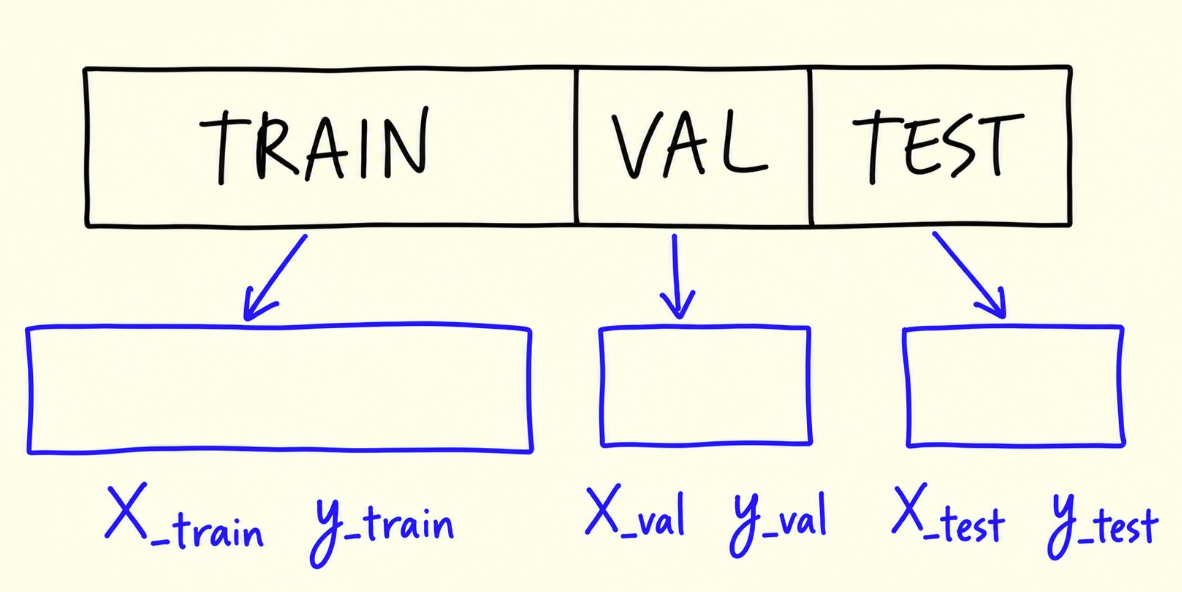
>
>---

<br><br>

---

## 1.1. Calculating the Sizes of the Parts



In [3]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

print(f"Total: {n},   -   Validation: {n_val},  Test: {n_test}, Train: {n_train},   -   Total Sum: {n_val+n_test+n_train}")

Total: 11914,   -   Validation: 2382,  Test: 2382, Train: 7150,   -   Total Sum: 11914


<br><br>

---

## 1.2. Taking a Part of the DataFrame with `iloc`



In [4]:
df_train = df.iloc[:n_train]
df_val = df.iloc[n_train:n_train + n_val]
df_test = df.iloc[n_train + n_val:]

In [5]:
df_train.head(3)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350


In [6]:
df_val.head(3)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
7150,lincoln,navigator,2015,regular_unleaded,365.0,6.0,automatic,rear_wheel_drive,4.0,luxury,large,4dr_suv,20,15,61,63645
7151,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,rear_wheel_drive,4.0,luxury,large,4dr_suv,22,16,61,63195
7152,lincoln,navigator,2016,regular_unleaded,380.0,6.0,automatic,four_wheel_drive,4.0,luxury,large,4dr_suv,19,15,61,76650


In [7]:
df_test.head(3)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
9532,chevrolet,silverado_1500,2015,regular_unleaded,355.0,8.0,automatic,rear_wheel_drive,4.0,NaN,large,crew_cab_pickup,23,16,1385,47575
9533,chevrolet,silverado_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,rear_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,24,18,1385,31940
9534,chevrolet,silverado_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,rear_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,24,18,1385,38335


> - If we take a sharp look at the "Make" Column either on "df_test" or "df_val" we can see that since all data was ordered by make.
>
> - We now have BMW only in "df_val" but not in "df_test".
>
> - We only have Porsche in "df_test" but not in "df_val".
>
> - We need to shuffle the rows of the data set in order to have all "makes" values in the three splitted datasets.

<br><br>

---

## 1.3. Shuffling the Records



In [8]:
idx = np.arange(n)

np.random.shuffle(idx)

idx

array([ 8077, 10692,  9139, ...,   168,  6454,  2441], shape=(11914,))

In [9]:
df.iloc[idx[:5]]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
8077,dodge,ram_150,1993,regular_unleaded,230.0,8.0,manual,four_wheel_drive,2.0,NaN,large,extended_cab_pickup,15,12,1851,2008
10692,ford,transit_wagon,2015,flex-fuel_(unleaded/e85),275.0,6.0,automatic,rear_wheel_drive,3.0,"flex_fuel,diesel",large,passenger_van,19,14,5657,40830
9139,toyota,sequoia,2017,regular_unleaded,381.0,8.0,automatic,four_wheel_drive,4.0,NaN,large,4dr_suv,17,13,2031,65215
839,saab,9-3,2010,premium_unleaded_(recommended),207.0,4.0,manual,front_wheel_drive,2.0,luxury,compact,convertible,29,20,376,39990
9961,cadillac,srx,2014,regular_unleaded,308.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,23,16,1624,50955


In [10]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

# Now let's take a look at our three datasets...
display(df_train.head())
display(df_val.head())
display(df_test.head())

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
8077,dodge,ram_150,1993,regular_unleaded,230.0,8.0,manual,four_wheel_drive,2.0,NaN,large,extended_cab_pickup,15,12,1851,2008
10692,ford,transit_wagon,2015,flex-fuel_(unleaded/e85),275.0,6.0,automatic,rear_wheel_drive,3.0,"flex_fuel,diesel",large,passenger_van,19,14,5657,40830
9139,toyota,sequoia,2017,regular_unleaded,381.0,8.0,automatic,four_wheel_drive,4.0,NaN,large,4dr_suv,17,13,2031,65215
839,saab,9-3,2010,premium_unleaded_(recommended),207.0,4.0,manual,front_wheel_drive,2.0,luxury,compact,convertible,29,20,376,39990
9961,cadillac,srx,2014,regular_unleaded,308.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,23,16,1624,50955


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
9681,mercedes-benz,slk-class,2016,premium_unleaded_(required),416.0,8.0,automatic,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,convertible,28,19,617,72600
4194,ford,escape,2015,premium_unleaded_(recommended),178.0,4.0,automatic,all_wheel_drive,4.0,crossover,compact,4dr_suv,30,22,5657,27400
1332,ford,aerostar,1995,regular_unleaded,135.0,6.0,automatic,rear_wheel_drive,3.0,NaN,midsize,passenger_minivan,22,15,5657,2000
8977,hyundai,santa_fe_sport,2016,regular_unleaded,190.0,4.0,automatic,all_wheel_drive,4.0,crossover,midsize,4dr_suv,25,19,1439,26700
1795,volkswagen,beetle_convertible,2014,regular_unleaded,170.0,5.0,automatic,front_wheel_drive,2.0,NaN,compact,convertible,27,21,873,27295


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
7191,volkswagen,new_beetle,2008,regular_unleaded,150.0,5.0,automatic,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,29,20,873,20525
3552,land_rover,defender,1995,regular_unleaded,182.0,8.0,manual,four_wheel_drive,2.0,luxury,compact,2dr_suv,15,12,258,30709
2783,chevrolet,colorado,2015,regular_unleaded,305.0,6.0,automatic,four_wheel_drive,4.0,NaN,compact,crew_cab_pickup,24,17,1385,32085
3365,mazda,cx-5,2015,regular_unleaded,184.0,4.0,automatic,all_wheel_drive,4.0,crossover,midsize,4dr_suv,30,24,586,24395
10916,hyundai,tucson,2016,regular_unleaded,175.0,4.0,automated_manual,all_wheel_drive,4.0,crossover,compact,4dr_suv,28,24,1439,27550


<br>

> - The problem we are facing now is that **this dataset is not reproducible**. If we use `np.random.shuffle(idx)` once again, the whole series of numbers will be different. Therefore our splitted dataset will be different each time.
>
> - We need to use a `Random Seed` in order to make the split of the dataset reproducible. And obtain the same rows for each splitted dataset, each time.

<br>

In [11]:
# First execution
idx = np.arange(n)

np.random.seed(42)
np.random.shuffle(idx)

idx

array([3995, 7474, 7300, ..., 5390,  860, 7270], shape=(11914,))

In [12]:
# Second execution
idx = np.arange(n)

np.random.seed(42)
np.random.shuffle(idx)

idx

array([3995, 7474, 7300, ..., 5390,  860, 7270], shape=(11914,))

In [13]:
# Now we can perform our split of the dataset 
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

display(df_train.head())
print('\n'*2)
display(df_val.head())
print('\n'*2)
display(df_test.head())

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3995,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,NaN,large,4dr_suv,18,13,549,29695
7474,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,38,25,873,30495
7300,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,28,19,2202,37650
3148,chevrolet,cruze,2015,regular_unleaded,138.0,4.0,manual,front_wheel_drive,4.0,NaN,midsize,sedan,36,25,1385,16170
747,volvo,740,1991,regular_unleaded,162.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",midsize,sedan,20,17,870,2000


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3416,mazda,cx-9,2016,regular_unleaded,227.0,4.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,28,22,586,31520
307,nissan,370z,2015,premium_unleaded_(required),350.0,6.0,automatic,rear_wheel_drive,2.0,"factory_tuner,high-performance",compact,coupe,26,19,2009,46790
3908,honda,element,2011,regular_unleaded,166.0,4.0,automatic,all_wheel_drive,4.0,crossover,compact,4dr_suv,24,19,2202,24185
9065,chrysler,sebring,2009,regular_unleaded,173.0,4.0,automatic,front_wheel_drive,4.0,flex_fuel,midsize,sedan,30,21,1013,21810
348,nissan,370z,2017,premium_unleaded_(required),332.0,6.0,manual,rear_wheel_drive,2.0,high-performance,compact,coupe,26,18,2009,33570


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
5510,pontiac,grand_prix,2008,regular_unleaded,303.0,8.0,automatic,front_wheel_drive,4.0,"factory_tuner,high-performance",large,sedan,25,16,210,29325
5330,volkswagen,gli,2008,premium_unleaded_(required),200.0,4.0,automated_manual,front_wheel_drive,4.0,performance,compact,sedan,29,22,873,25375
4531,ford,f-150,2016,flex-fuel_(unleaded/e85),282.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,23,17,5657,36565
365,mazda,3,2015,regular_unleaded,184.0,4.0,automatic,front_wheel_drive,4.0,performance,compact,sedan,39,28,586,24895
11892,bmw,z4_m,2008,premium_unleaded_(required),330.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,23,15,3916,50400


In [14]:
# Now we'll check the length of each splitted dataset

print(f"TRAIN: {n_train}={len(df_train)},   VALIDATION: {n_val}={len(df_val)},   TEST: {n_test}={len(df_test)}")

TRAIN: 7150=7150,   VALIDATION: 2382=2382,   TEST: 2382=2382


<br><br>

---

## 1.4. Reseting the Index

<br><br>

>The next step we need to perform is to `reset the index of the three splitted datasets`. Since we don't really need to know the original index of each splitted dataset.

In [15]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# -----------------------------------------
# Now let's see our changes...
display(df_train.head(3))
print('\n'*2)
display(df_val.head(3))
print('\n'*2)
display(df_test.head(3))

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,NaN,large,4dr_suv,18,13,549,29695
1,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,38,25,873,30495
2,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,28,19,2202,37650


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,mazda,cx-9,2016,regular_unleaded,227.0,4.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,28,22,586,31520
1,nissan,370z,2015,premium_unleaded_(required),350.0,6.0,automatic,rear_wheel_drive,2.0,"factory_tuner,high-performance",compact,coupe,26,19,2009,46790
2,honda,element,2011,regular_unleaded,166.0,4.0,automatic,all_wheel_drive,4.0,crossover,compact,4dr_suv,24,19,2202,24185


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,pontiac,grand_prix,2008,regular_unleaded,303.0,8.0,automatic,front_wheel_drive,4.0,"factory_tuner,high-performance",large,sedan,25,16,210,29325
1,volkswagen,gli,2008,premium_unleaded_(required),200.0,4.0,automated_manual,front_wheel_drive,4.0,performance,compact,sedan,29,22,873,25375
2,ford,f-150,2016,flex-fuel_(unleaded/e85),282.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,23,17,5657,36565


<br><br>

---

## 1.5. Target Vector


In [16]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

# -------------------------------------------
# Now let's see our new target vectors...
print(y_train, '\n')
print(y_val, '\n')
print(y_test, '\n')

[10.29876764 10.32535081 10.53611479 ...  9.83258214  9.96062374
 10.28537692] 

[10.35840927 10.75344616 10.09352923 ... 10.34016059 10.18229284
 10.65374731] 

[10.28622977 10.14155912 10.50687413 ... 10.22524491 10.67523794
 10.48796319] 



<br><br>

---

## 1.6. Feature Matrix



In [17]:
# Now we need to delete the "msrp" column. Otherwise the model will be trained knowing the target values.
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [18]:
X_train = df_train.values
X_val = df_val.values
X_test = df_test.values

print(f"- Train Shape: {X_train.shape}, Dimensions: {X_train.ndim}\n")
print(f"- Validation Shape: {X_val.shape}, Dimensions: {X_val.ndim}\n")
print(f"- Test Shape: {X_test.shape}, Dimensions: {X_test.ndim}")

- Train Shape: (7150, 15), Dimensions: 2

- Validation Shape: (2382, 15), Dimensions: 2

- Test Shape: (2382, 15), Dimensions: 2


<br><br>

---

# 2. Simple Linear Regression

<br><br>

In [19]:
# Let's pick up just one row from the feature matrix
df_train.iloc[10]

make                            toyota
model                            yaris
year                              2015
engine_fuel_type      regular_unleaded
engine_hp                        106.0
engine_cylinders                   4.0
transmission_type               manual
driven_wheels        front_wheel_drive
number_of_doors                    2.0
market_category              hatchback
vehicle_size                   compact
vehicle_style            2dr_hatchback
highway_mpg                         37
city_mpg                            30
popularity                        2031
Name: 10, dtype: object

In [20]:
# Create a list with "engine_hp", "city_mpg" and "popularity" values
xi = [106, 30, 2031]

# Now we need the weights for our model
w0 = 7.17
w = [0.01, 0.04, 0.002]

<br>

Remember that for this example `i` in the following formulas is equal to `10`. Which is the select row from our *feature matrix*.

<br>

 - The general calculation we need to perform is:

$$\LARGE g(x_i) = w_0 + w_1 \cdot x_{i1} + w_2 \cdot x_{i2} + w_3 \cdot x_{i3} $$

<br>

 - the sum form of the upper calculation is:

$$\LARGE g(x_i) = w_0 + \sum_{j=1}^{3}w_j \cdot x_{ij}$$

<br>

In [21]:
# Now let's put the upper formula in code
def linear_regression(xi):
    n = len(xi)
    pred = w0

    for j in range(n):
        pred += w[j] * xi[j]

    return pred

In [22]:
# The predicted price for our Toyota - Yaris of 2015 is:
y = linear_regression(xi)
y

13.492

In [23]:
# Since we used logarithms to reduce the effect of Outliers
# now we need to execute the inverse process to get the real value of this car
real_y = np.expm1(y)
real_y

np.float64(723603.3180935134)

<br><br>

---

# 3. Linear Regression - Vector Form



$$\LARGE g(x_i) = w_0 + \sum_{j=1}^{3}w_j \cdot x_{ij}$$



<br><br>

---

## 3.1. Dot Product



In [24]:
def dot(xi, w):
    n = len(xi)
    res = 0.0

    for j in range(n):
        res += w[j] * xi[j]
    return res

def linear_regression(xi):
    return w0 + dot(xi, w)

In [25]:
y1 = linear_regression(xi)
y1

13.492

<br><br>

---

## 3.2. The Fictional Feature


>---
>
>We can make it even shorter. The bias term $w_0$ is kind of hanging out there all alone, without a feature.
>**Let's bring it into the dot product**: we imagine that there is one extra feature of our car, $x_{i0}$, and this feature is always 1.
>
>- Then the vector of weights becomes $w_0$, $w_1$, $w_2$ and so on up to $w_n$.
>   - It is an `n+1 dimensional` vector now.
>- And the **vector of features** becomes $x_{i0}$, $x_{i1}$, $x_{i2}$ and so on,
>   - where $x_{i0}$ is equal to `1`.
>
>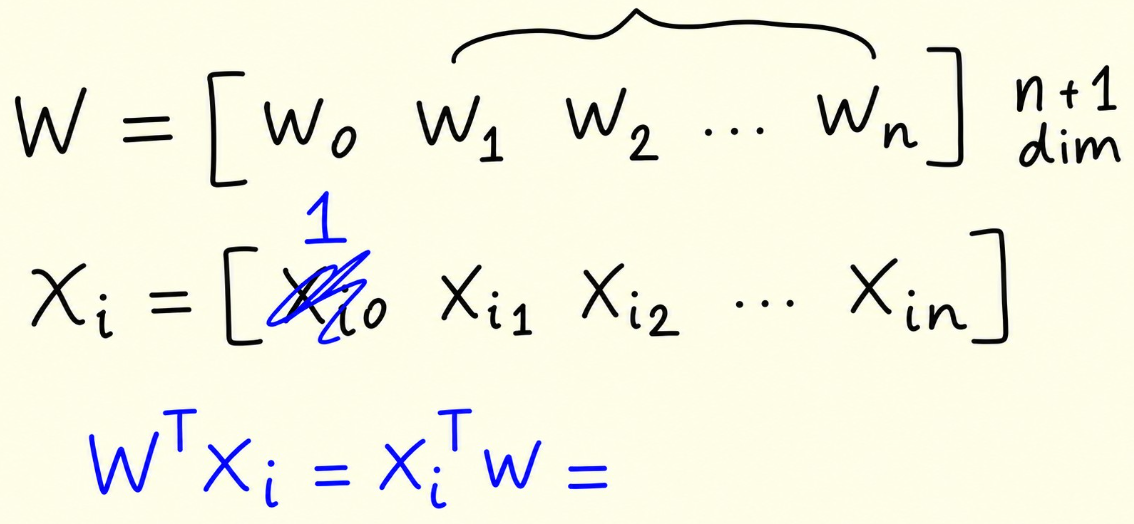
>
>---

In [26]:
# Create a new variable for all the weights, including "w0"
w_new = [w0] + w
w_new

[7.17, 0.01, 0.04, 0.002]

In [27]:
# Now we create our new function for the whole matrix
def linear_regression_full(xi):
    xi = [1] + xi
    return dot(xi, w_new)

In [28]:
linear_regression_full(xi)

13.492

<br>

---

<br>

In [29]:
# Now it's time to get a bit larger amount of data, in this case will take 3 rows...
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

# let's converted into a numpy array...
X = np.array([x1, x2, x10])
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

In [30]:
# and now we configure our new vector of weights
w_new = np.array(w_new)
w_new

array([7.17e+00, 1.00e-02, 4.00e-02, 2.00e-03])

In [31]:
# Now we'll perform a linear regression calculation using numpy method ".dot"
X.dot(w_new)

array([12.38 , 13.552, 12.312])